In [29]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


### 1. Загрузка и первичный осмотр

In [30]:
df = pd.read_csv("dataset.csv")
assert "popularity" in df.columns, "В данных отсутствует таргет popularity"
print(f"Размер: {df.shape[0]:,} строк, {df.shape[1]} колонок")
print("Полные дубликаты:", df.duplicated().sum())
print("Повторы track_id:", df["track_id"].duplicated().sum())
display(df.head())
df.info()
display(df.isna().sum().sort_values(ascending=False).to_frame("Пропуски"))


Размер: 114,000 строк, 21 колонок
Полные дубликаты: 0
Повторы track_id: 24259


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

,Пропуски
artists,1
track_name,1
album_name,1
Unnamed: 0,0
track_id,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0


В датасете 114 тысяч записей и повторяются track_id, это важно учитывать при разбиении. В нескольких текстовых колонках есть единичные пропуски. Из идентификаторов и названий извлечём компактные признаки.


### 2. EDA: распределение таргета


,popularity
count,114000.000000
mean,33.238535
std,22.305078
min,0.000000
25%,17.000000
50%,35.000000
75%,50.000000
max,100.000000


Треки с popularity=0: 14.1%


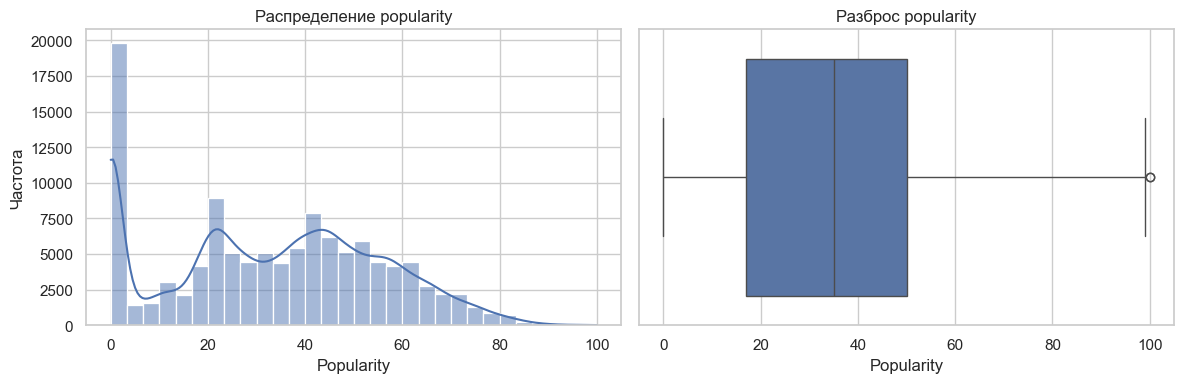

In [31]:
display(df["popularity"].describe().to_frame("popularity"))
print(f"Треки с popularity=0: {(df['popularity']==0).mean():.1%}")
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(df["popularity"], bins=30, kde=True, ax=axes[0])
axes[0].set(title="Распределение popularity", xlabel="Popularity", ylabel="Частота")
sns.boxplot(x=df["popularity"], ax=axes[1])
axes[1].set(title="Разброс popularity", xlabel="Popularity")
plt.tight_layout(); plt.show()


popularity ограничен диапазоном от 0 до 100; медиана и среднее будут показаны выше. Нули и возможная асимметрия влияют на ошибки, поэтому далее оцениваем модели сразу по MAE, RMSE и R^2.


### EDA: жанр и явный контент


,mean,median,count
track_genre,,,
pop-film,59.283,60.0,1000
k-pop,56.896,60.0,1000
chill,53.651,57.0,1000
sad,52.379,54.0,1000
grunge,49.594,55.0,1000
indian,49.539,49.0,1000
anime,48.772,50.0,1000
emo,48.128,51.0,1000
sertanejo,47.866,47.0,1000


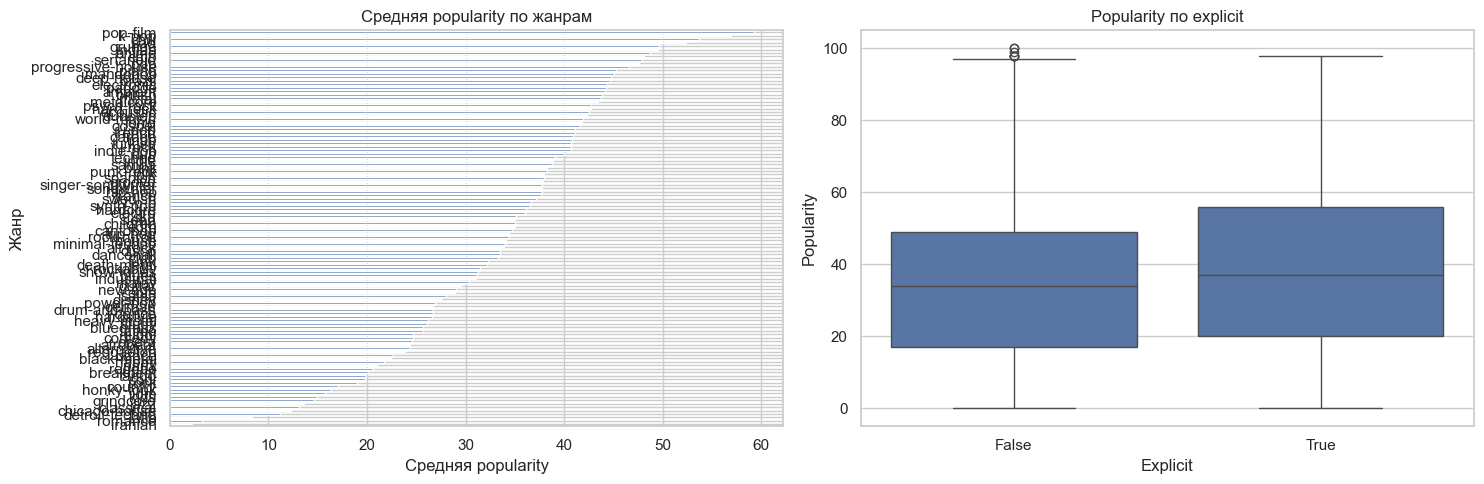

In [32]:
genre_summary = df.groupby("track_genre")["popularity"].agg(["mean","median","count"]).sort_values("mean",ascending=False)
display(genre_summary.head(10))
fig, axes = plt.subplots(1,2,figsize=(15,5))
genre_summary["mean"].sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Средняя popularity по жанрам", xlabel="Средняя popularity", ylabel="Жанр")
sns.boxplot(data=df, x="explicit", y="popularity", ax=axes[1])
axes[1].set(title="Popularity по explicit", xlabel="Explicit", ylabel="Popularity")
plt.tight_layout(); plt.show()


Жанры могут заметно отличаться по средней популярности, поэтому track_genre стоит сохранить как категориальный предиктор. У распределения explicit/non-explicit важно смотреть не только среднее, но и разброс.


### EDA: аудиохарактеристики


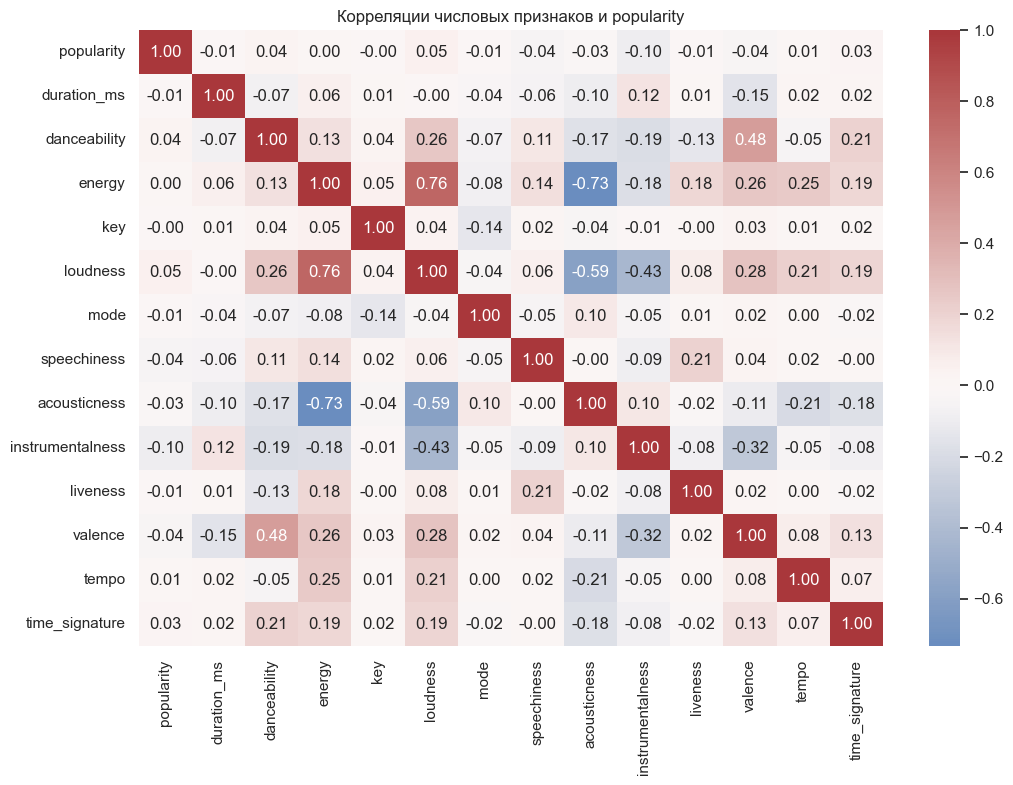

,Корреляция с popularity
instrumentalness,-0.095139
loudness,0.050423
speechiness,-0.044927
valence,-0.040534
danceability,0.035448
time_signature,0.031073
acousticness,-0.025472
mode,-0.013931
tempo,0.013205
duration_ms,-0.007101


In [33]:
numeric = df.select_dtypes(include=np.number).drop(columns=["Unnamed: 0"],errors="ignore")
corr = numeric.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12,8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Корреляции числовых признаков и popularity")
plt.show()
display(corr["popularity"].drop("popularity").sort_values(key=abs,ascending=False).to_frame("Корреляция с popularity"))


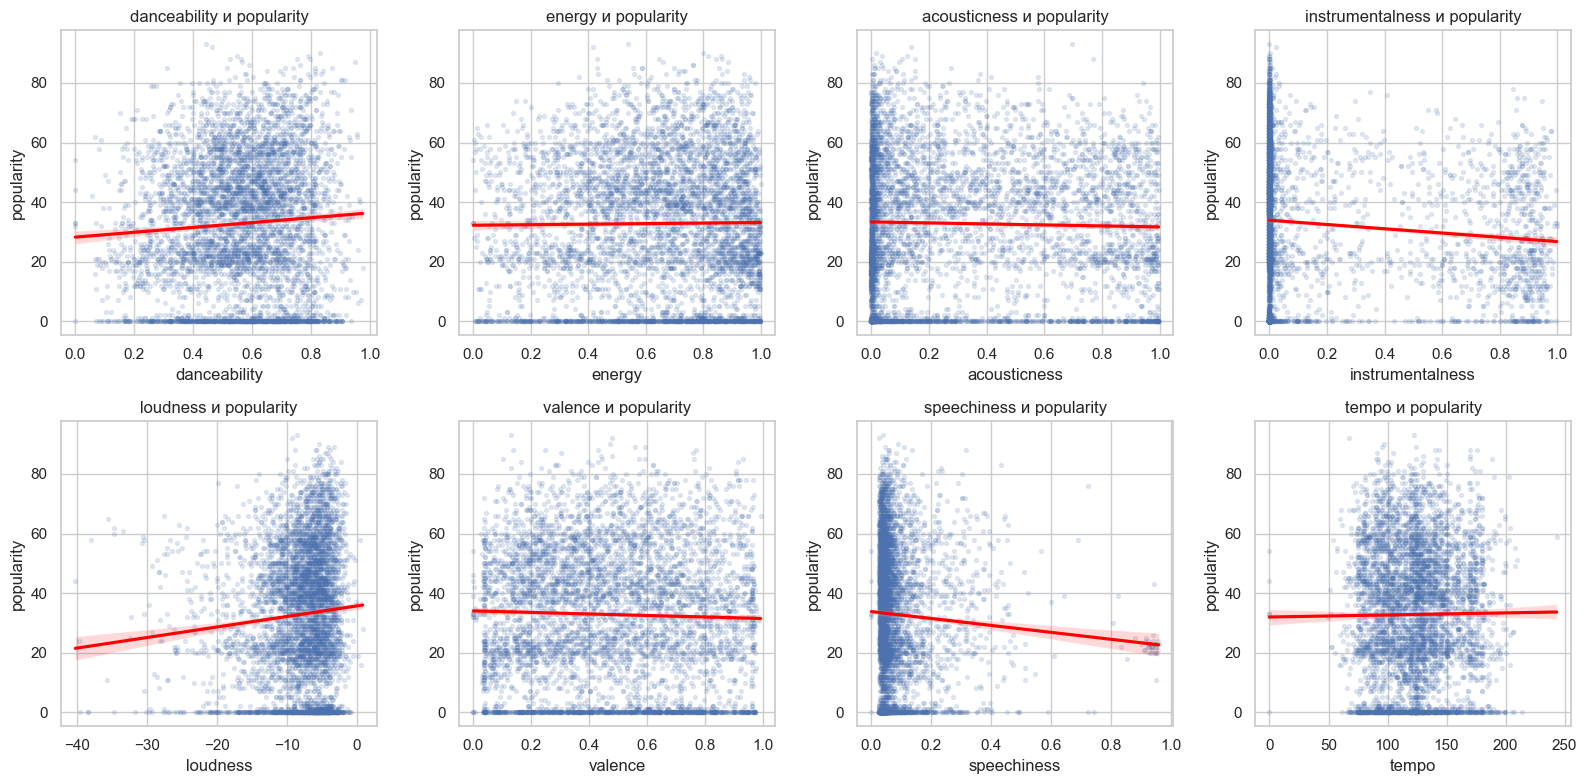

In [34]:
audio_cols = ["danceability","energy","acousticness","instrumentalness","loudness","valence","speechiness","tempo"]
fig, axes = plt.subplots(2,4,figsize=(16,8))
for col, ax in zip(audio_cols, axes.flat):
    sns.regplot(data=df.sample(min(5000,len(df)),random_state=RANDOM_STATE), x=col, y="popularity",
                scatter_kws={"alpha":0.15,"s":8}, line_kws={"color":"red"}, ax=ax)
    ax.set_title(f"{col} и popularity")
plt.tight_layout(); plt.show()


Таблица покажет числовые признаки с наиболее заметной линейной связью с таргетом. Точки и линии тренда помогают увидеть, если связь слабая или нелинейная. Корреляция не означает причинность, а слабая корреляция отдельного признака не исключает его полезности в комбинации с жанром и другими характеристиками.


### 3. Feature Engineering

In [35]:
def make_features(frame):
    out = frame.copy()
    out["duration_min"] = out["duration_ms"] / 60000
    out["artist_count"] = out["artists"].fillna("").astype(str).apply(lambda s: len([x for x in s.split(";") if x.strip()]))
    out["track_name_length"] = out["track_name"].fillna("").astype(str).str.len()
    out["album_name_length"] = out["album_name"].fillna("").astype(str).str.len()
    return out.drop(columns=["Unnamed: 0","track_id","duration_ms","artists","album_name","track_name"],errors="ignore")

groups = df["track_id"].astype(str).to_numpy()
X = make_features(df.drop(columns="popularity"))
y = df["popularity"].astype(float)
new_numeric = ["duration_min","artist_count","track_name_length","album_name_length"]
new_corr = pd.concat([X[new_numeric],y.rename("popularity")],axis=1).corr()["popularity"].drop("popularity")
display(new_corr.sort_values(key=abs,ascending=False).to_frame("Корреляция нового признака с popularity"))


,Корреляция нового признака с popularity
album_name_length,-0.089783
track_name_length,-0.070608
duration_min,-0.007101
artist_count,0.006842


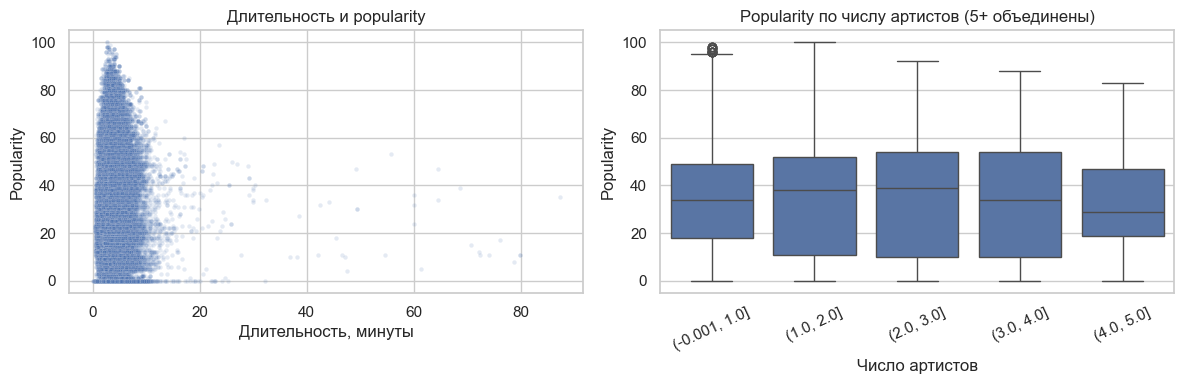

In [36]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(x=X["duration_min"],y=y,alpha=0.15,s=10,ax=axes[0])
axes[0].set(title="Длительность и popularity",xlabel="Длительность, минуты",ylabel="Popularity")
sns.boxplot(x=pd.cut(X["artist_count"].clip(upper=5), bins=[0,1,2,3,4,5], include_lowest=True),y=y,ax=axes[1])
axes[1].set(title="Popularity по числу артистов (5+ объединены)",xlabel="Число артистов",ylabel="Popularity")
axes[1].tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.show()


Парные корреляции новых признаков и графики помогают проверить, есть ли в созданных переменных отдельный простой сигнал. Финальную полезность оцениваем только на отложенных данных и в кросс-валидации, группируя одинаковые track_id.


### 4. Разделение без утечки по track_id

Так как один track_id может встречаться в нескольких строках, используем групповое разделение: один трек не попадёт одновременно в train и test. Доля теста около 20%. Кросс-валидация далее также будет групповой и пятифолдовой.


In [37]:
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=RANDOM_STATE)
train_idx,test_idx = next(splitter.split(X,y,groups=groups))
X_train,X_test = X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test = y.iloc[train_idx],y.iloc[test_idx]
g_train,g_test = groups[train_idx],groups[test_idx]
assert set(g_train).isdisjoint(set(g_test)), "Обнаружена утечка track_id между train и test"
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Train:",X_train.shape,"Test:",X_test.shape)
print("Общие track_id между train и test:",len(set(g_train)&set(g_test)))
print("Признаки:",X_train.columns.tolist())


Train: (91323, 18) Test: (22677, 18)
Общие track_id между train и test: 0
Признаки: ['explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_min', 'artist_count', 'track_name_length', 'album_name_length']


Числовые пропуски заполним медианой и масштабируем, категориальные — наиболее частым значением и one-hot кодированием.


In [38]:
num_pipe = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
cat_pipe = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
prep = ColumnTransformer([("num",num_pipe,num_cols),("cat",cat_pipe,cat_cols)],sparse_threshold=0)


### 5. Простая регрессия и модели разных семейств

In [39]:
models = {
    "Baseline: среднее": DummyRegressor(strategy="mean"),
    "Ridge (линейная)": Ridge(alpha=10.0),
    "Дерево решений": DecisionTreeRegressor(max_depth=18,min_samples_leaf=20,random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=150,learning_rate=0.08,max_leaf_nodes=31,l2_regularization=1.0,early_stopping=True,random_state=RANDOM_STATE),
    "Нейронная сеть MLP": MLPRegressor(hidden_layer_sizes=(64,32),alpha=0.001,learning_rate_init=0.001,early_stopping=True,max_iter=100,random_state=RANDOM_STATE)
}
cv = GroupKFold(n_splits=5)
scoring = {"mae":"neg_mean_absolute_error","rmse":"neg_root_mean_squared_error","r2":"r2"}
pipelines = {}
rows = []
for name,estimator in models.items():
    pipe = Pipeline([("prep",prep),("model",estimator)])
    pipelines[name] = pipe
    scores = cross_validate(pipe,X_train,y_train,groups=g_train,cv=cv,scoring=scoring,n_jobs=-1,return_train_score=False)
    rows.append({"Модель":name,"MAE среднее":-scores["test_mae"].mean(),"MAE std":scores["test_mae"].std(),"RMSE среднее":-scores["test_rmse"].mean(),"RMSE std":scores["test_rmse"].std(),"R^2 среднее":scores["test_r2"].mean(),"R^2 std":scores["test_r2"].std()})
cv_results = pd.DataFrame(rows).sort_values("RMSE среднее").reset_index(drop=True)
display(cv_results)
best_name = cv_results.loc[0,"Модель"]
best_model = pipelines[best_name]
print("Победитель по среднему RMSE на 5 фолдах:",best_name)


,Модель,MAE среднее,MAE std,RMSE среднее,RMSE std,R^2 среднее,R^2 std
0,Нейронная сеть MLP,12.264038,0.112373,17.200748,0.187399,0.406872,0.010494
1,HistGradientBoosting,12.991238,0.097675,17.357223,0.141366,0.396056,0.006886
2,Ridge (линейная),14.144391,0.069595,19.206725,0.119148,0.260500,0.005335
3,Дерево решений,15.569976,0.098161,19.932782,0.072365,0.203530,0.002695
4,Baseline: среднее,18.906781,0.054781,22.337133,0.061267,-0.000203,0.000265


Победитель по среднему RMSE на 5 фолдах: Нейронная сеть MLP


Кросс-валидация сравнивает модели на одних и тех же групповых фолдах. Победитель выбирается по среднему RMSE. MAE показывает типичную абсолютную ошибку в пунктах popularity, а R^2 — долю объяснённой вариации. Стандартные отклонения показывают стабильность по фолдам.


### 6. Финальная оценка и важность признаков


Выбранная модель: Нейронная сеть MLP
MAE: 12.128 пунктов popularity
RMSE: 17.060
R^2: 0.408


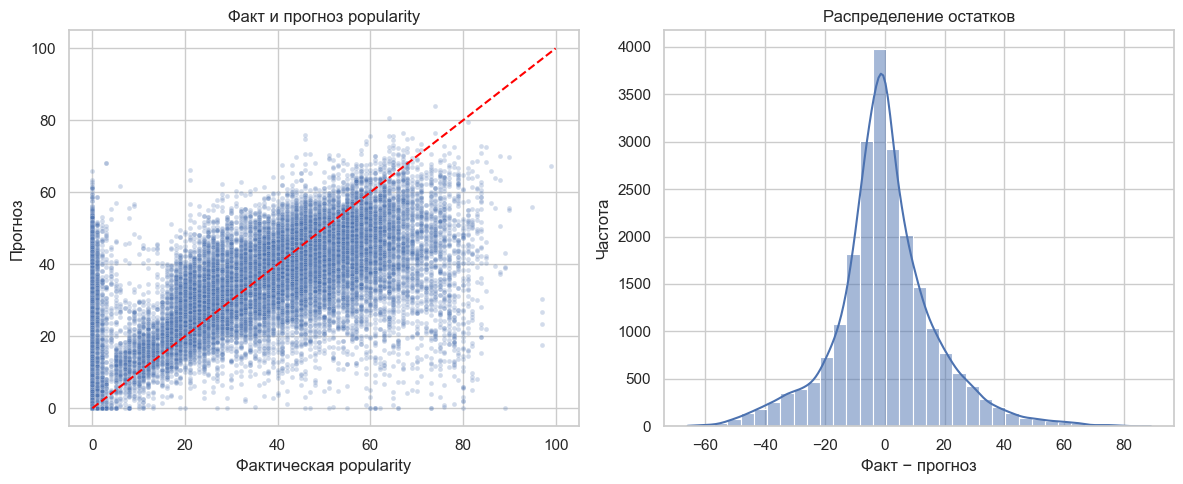

In [40]:
best_model.fit(X_train,y_train)
y_pred_raw = best_model.predict(X_test)
y_pred = np.clip(y_pred_raw,0,100)
print("Выбранная модель:",best_name)
print(f"MAE: {mean_absolute_error(y_test,y_pred):.3f} пунктов popularity")
print(f"RMSE: {mean_squared_error(y_test,y_pred)**0.5:.3f}")
print(f"R^2: {r2_score(y_test,y_pred):.3f}")
fig,axes = plt.subplots(1,2,figsize=(12,5))
sns.scatterplot(x=y_test,y=y_pred,alpha=0.25,s=12,ax=axes[0])
axes[0].plot([0,100],[0,100],color="red",linestyle="--")
axes[0].set(title="Факт и прогноз popularity",xlabel="Фактическая popularity",ylabel="Прогноз")
residuals = y_test.to_numpy()-y_pred
sns.histplot(residuals,bins=35,kde=True,ax=axes[1])
axes[1].set(title="Распределение остатков",xlabel="Факт − прогноз",ylabel="Частота")
plt.tight_layout(); plt.show()


MAE в среднем выражается в пунктах popularity. RMSE сильнее штрафует крупные ошибки. На scatter-графике хорошая модель располагает точки ближе к диагонали.


,Permutation importance (снижение MAE при перемешивании)
track_genre,7.879418
album_name_length,2.020743
track_name_length,0.820812
energy,0.681211
acousticness,0.599624
loudness,0.584586
danceability,0.385546
valence,0.366612
speechiness,0.330976
artist_count,0.306294


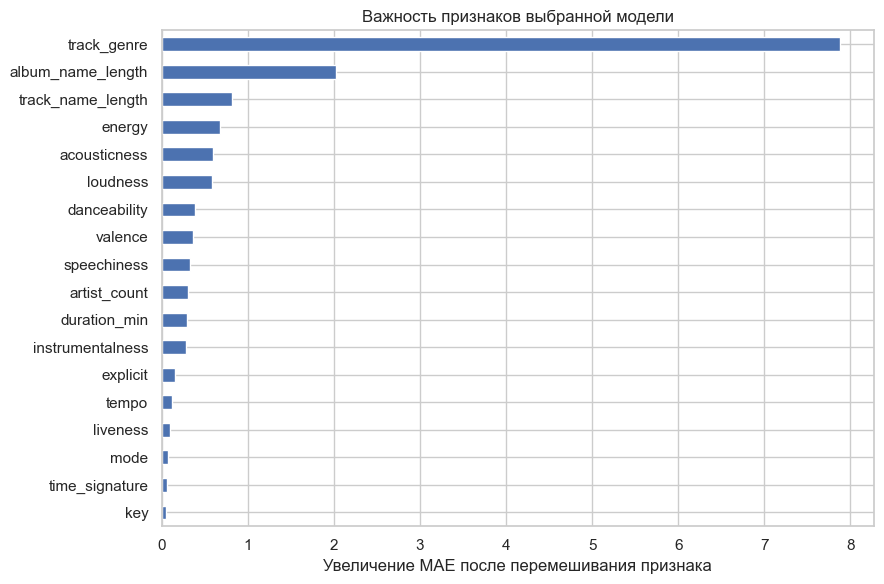

In [41]:
# Для приемлемого времени расчёта важность оценивается на случайной подвыборке holdout.
importance_n = min(8000,len(X_test))
X_imp = X_test.sample(importance_n,random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]
perm = permutation_importance(best_model,X_imp,y_imp,scoring="neg_mean_absolute_error",n_repeats=5,random_state=RANDOM_STATE,n_jobs=-1)
importance = pd.Series(perm.importances_mean,index=X_test.columns).sort_values(ascending=False)
display(importance.to_frame("Permutation importance (снижение MAE при перемешивании)"))
ax = importance.sort_values().plot.barh(figsize=(9,6),title="Важность признаков выбранной модели")
ax.set_xlabel("Увеличение MAE после перемешивания признака")
plt.tight_layout(); plt.show()


### 7. Финальные выводы по результатам запуска

#### Данные и EDA

- В датасете 114 000 строк и 21 колонка. Полных дубликатов нет, но track_id повторяется 24 259 раз. Групповое разбиение удержало одинаковые треки в одной части: пересечений track_id между train и test — 0.
- Пропуски есть только в artists, album_name и track_name — по одному значению в каждой колонке.
- popularity находится в диапазоне 0–100, среднее 33,24, медиана 35, стандартное отклонение 22,31. У 14,1% записей popularity равна нулю.
- Простые линейные корреляции аудиопризнаков с popularity невелики: наиболее заметны instrumentalness (−0,095) и loudness (+0,050). Следовательно, отдельные аудиохарактеристики не объясняют таргет линейно. Средняя популярность заметно различается по жанрам: например, pop-film — 59,3, k-pop — 56,9.
- Из созданных признаков наиболее заметная парная корреляция у длины названия альбома (−0,090), но корреляции новых признаков сами по себе слабые. Их совместная полезность оценивается моделью ниже.

#### Сравнение моделей

Победитель по RMSE в пятифолдовой GroupKFold кросс-валидации — нейронная сеть MLP: RMSE 17,20 ± 0,19, MAE 12,26 ± 0,11, R^2 0,407 ± 0,010. Это означает типичную абсолютную ошибку около 12 пунктов popularity, а объяснённая доля вариации составляет около 41%.

Градиентный бустинг оказался близок: RMSE 17,36 ± 0,14, MAE 12,99 ± 0,10, R^2 0,396 ± 0,007. Разница RMSE между MLP и бустингом — всего около 0,16 пункта, поэтому практическое преимущество MLP небольшое. Ridge и дерево решений уступили, а baseline по среднему ожидаемо дал худший результат (RMSE 22,34).

На отложенной групповой тестовой выборке MLP получил RMSE 17,06, MAE 12,13 и R^2 0,408. Метрики близки к средним CV, явного падения качества на holdout не видно.

#### Важность признаков и общий вывод

По permutation importance основным признаком оказалась track_genre: её перемешивание увеличило MAE примерно на 7,88 пункта. Далее идут album_name_length (2,02), track_name_length (0,82), energy (0,68) и acousticness (0,60). Остальные признаки дали заметно меньший вклад. Это важность для данной модели на holdout, а не причинное влияние; категория жанра может также отражать различия в аудиториях и структуре набора.

Итог: из проверенных вариантов выбираем MLP по минимальному среднему RMSE на пяти групповых фолдах. Ошибка около 12 popularity-пунктов по MAE и R^2 около 0,41 означают умеренную предсказательную способность: жанр даёт большую часть доступного сигнала, а только аудиохарактеристик недостаточно для точного прогноза. Близость CV и holdout поддерживает оценку качества, но небольшой отрыв от градиентного бустинга не следует переоценивать.
